In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

In [3]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
both = pd.read_csv(tables / "table_cocaine_vs_heroin.csv")
heroin_stats = pd.read_csv(tables / "table_heroin_cas_stats.csv")
heroin_scores = pd.read_csv(tables / "heroin_cas_scores.csv")


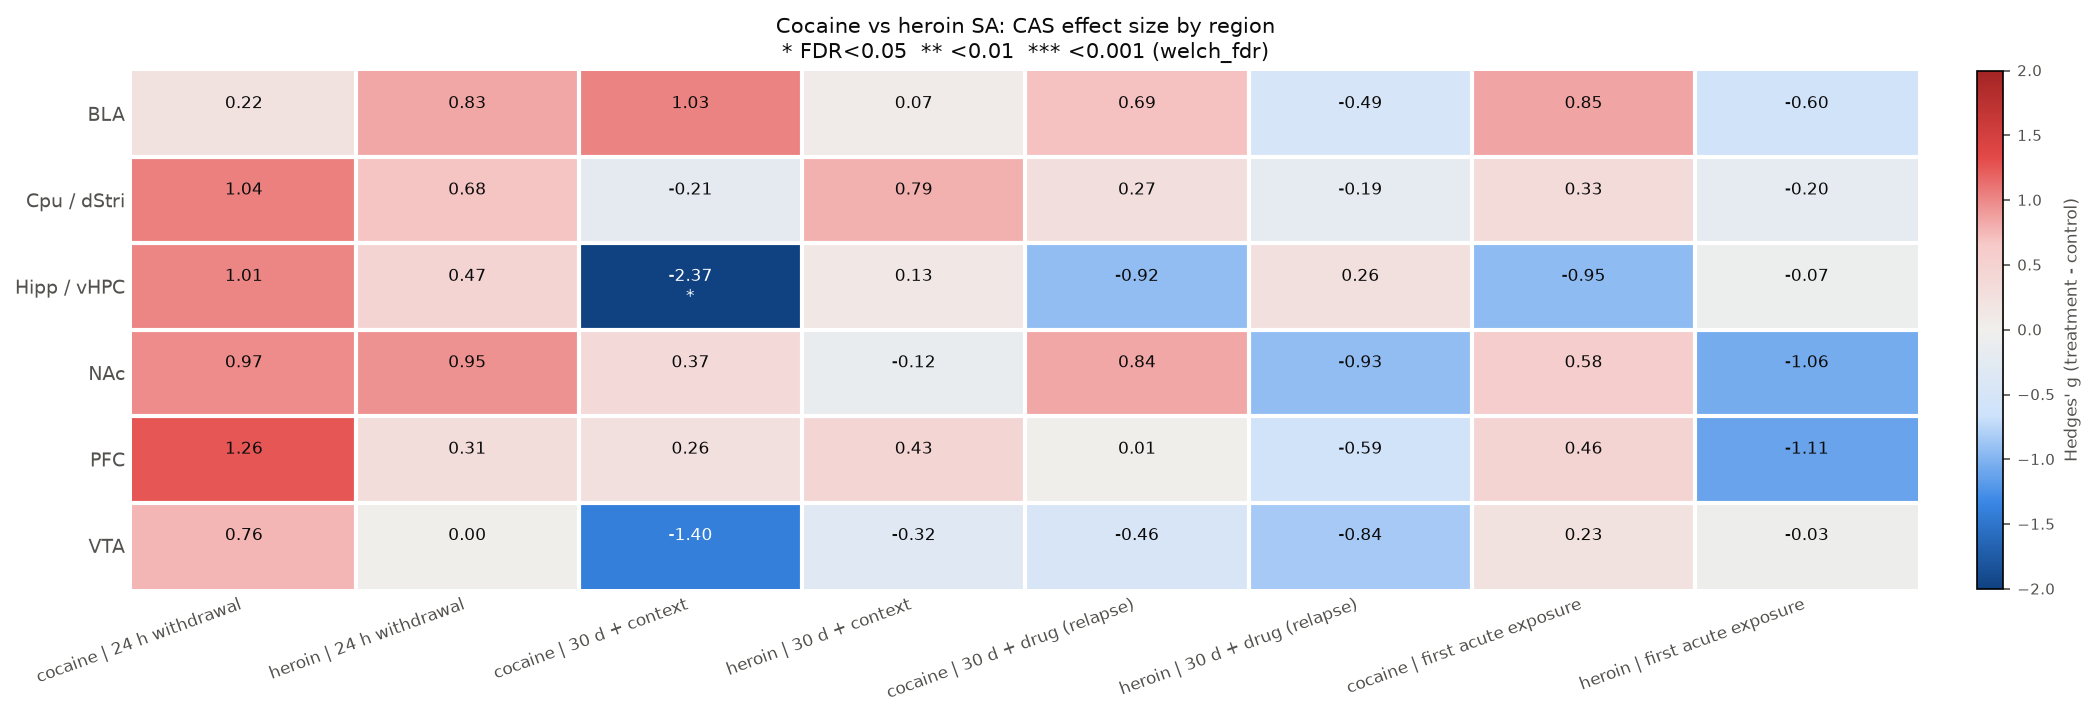

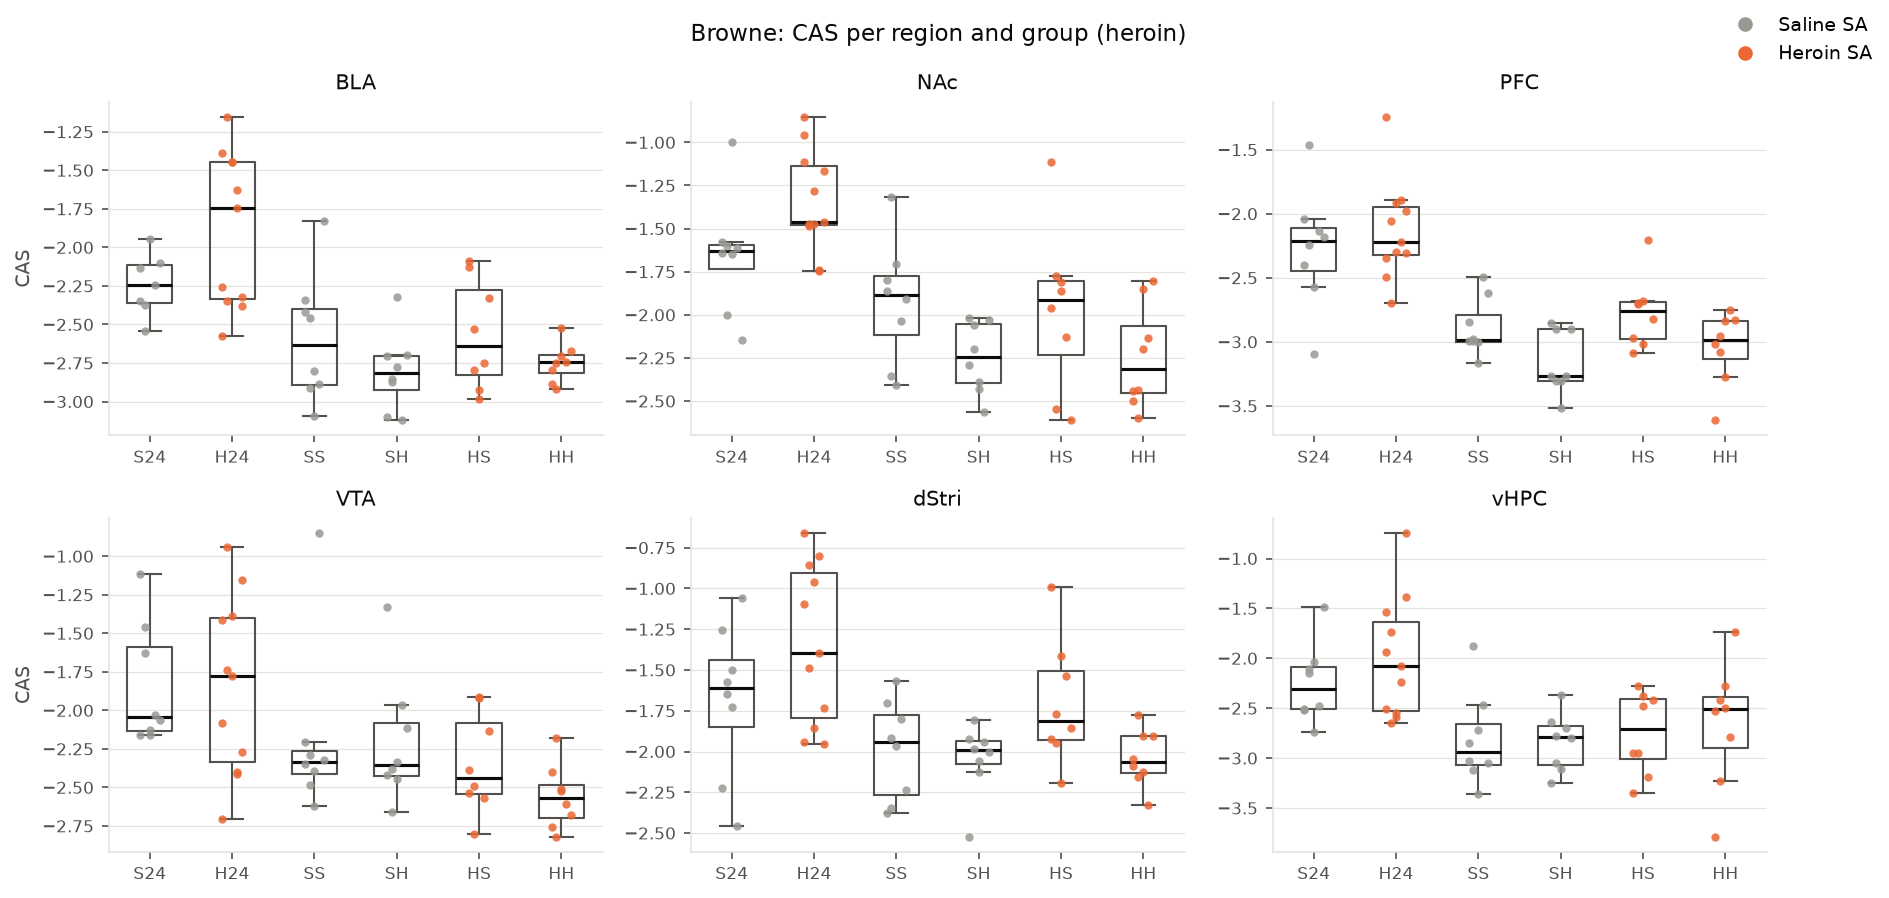

In [4]:
for name in ["fig5_cocaine_vs_heroin.png", "fig5b_heroin_cas_boxplots.png"]:
    display(Image(figs / name))

In [5]:
both.query("design == '24 h withdrawal'").pivot(
    index="region_pair", columns="drug", values=["g", "frac_aging_like"]).round(2)

g        frac_aging_like       
drug        cocaine heroin         cocaine heroin
region_pair                                      
BLA            0.22   0.83            0.47   0.79
Cpu / dStri    1.04   0.68            0.86   0.79
Hipp / vHPC    1.01   0.47            0.91   0.78
NAc            0.97   0.95            0.81   0.79
PFC            1.26   0.31            0.95   0.65
VTA            0.76   0.00            0.87   0.42

correlation: 0.04


Text(0.5, 1.0, "Hedges' g: cocaine vs heroin (each point = region x design)")

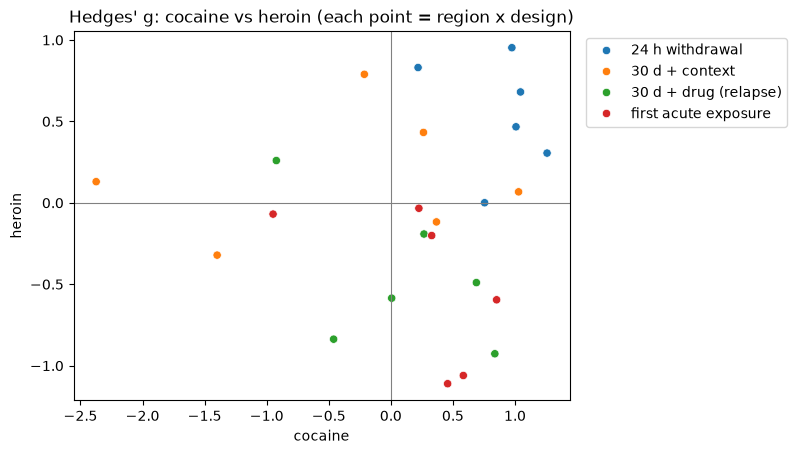

In [7]:
wide = both.pivot_table(index=["region_pair", "design"], columns="drug", values="g")
print("correlation:", wide.corr().iloc[0, 1].round(2))
sns.scatterplot(data=wide.reset_index(), x="cocaine", y="heroin", hue="design")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.title("Hedges' g: cocaine vs heroin (each point = region x design)")

Text(0.5, 1.0, 'Heroin dataset: 24 h cohort vs 30 d cohort (all groups)')

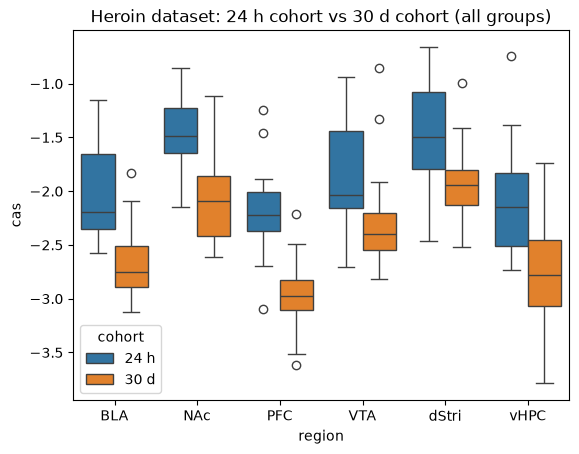

In [8]:
heroin_scores["cohort"] = heroin_scores["group"].map(lambda g: "24 h" if g.endswith("24") else "30 d")
sns.boxplot(data=heroin_scores, x="region", y="cas", hue="cohort")
plt.title("Heroin dataset: 24 h cohort vs 30 d cohort (all groups)")

In [9]:
heroin_stats[["region", "comparison", "n_treat", "n_ctrl", "g", "g_ci_low", "g_ci_high",
              "welch_fdr", "perm_fdr"]].round(3)

,region,comparison,n_treat,n_ctrl,g,g_ci_low,g_ci_high,welch_fdr,perm_fdr
0,BLA,H24 vs S24,11,7,0.831,0.126,1.903,0.329,0.506
1,BLA,HS vs SS,8,8,0.067,-1.003,1.122,0.970,0.954
2,BLA,HH vs SS,8,8,-0.490,-1.478,0.517,0.659,0.585
3,BLA,SH vs SS,8,8,-0.596,-1.540,0.275,0.569,0.506
4,NAc,H24 vs S24,11,8,0.953,0.136,2.201,0.329,0.316
5,NAc,HS vs SS,8,8,-0.117,-1.246,0.948,0.970,0.933
6,NAc,HH vs SS,8,8,-0.927,-2.325,-0.060,0.339,0.316
7,NAc,SH vs SS,8,8,-1.060,-2.432,-0.241,0.329,0.316
8,PFC,H24 vs S24,11,8,0.305,-0.721,1.274,0.826,0.748
9,PFC,HS vs SS,8,8,0.432,-0.514,1.528,0.695,0.734


In [10]:
pd.read_csv(tables / "table_heroin_cas_concordance.csv").pivot(
    index="region", columns="comparison", values="frac_aging_like").round(2)

comparison,H24 vs S24,HH vs SS,HS vs SS,SH vs SS
region,,,,
BLA,0.79,0.21,0.52,0.30
NAc,0.79,0.26,0.46,0.20
PFC,0.65,0.25,0.59,0.36
VTA,0.42,0.22,0.35,0.49
dStri,0.79,0.40,0.80,0.30
vHPC,0.78,0.52,0.51,0.42
